<h2>IS453 Financial Analytics</h2><h2>Group Assignment - Home Improvement Loan Scorecard</h2>

### Step 6: Scorecard Creation

This notebook follows `05_grouping_Screening.ipynb` (Step 5). It turns the 12 approved model characteristics into a points-based credit scorecard with **scorecardpy**, following the **Week 11 Lab**: `sc.woebin` / `sc.woebin_ply` (WOE encoding), `LogisticRegression`, `sc.scorecard` and `sc.scorecard_ply`. The profit analysis, cutoff choice and final scaling follow in `07_scorecard analysis.ipynb` (Step 7), which loads the model saved at the end of this notebook.

**Configuration approved by the user (2026-10-30)**

| Setting | Approved value |
|---|---|
| WOE binning source | The coarse-classing bins and WOE values approved in Step 5, reused unchanged (not re-optimised) |
| Train/test split | The Step 5 split in `data/train_test_split.csv` (70/30, stratified on `TARGET`, seed 186) |
| Logistic regression | Standard vs `class_weight='balanced'` compared with training-only cross-validation; the recommended one is fitted |
| Characteristics | The 12 final characteristics from Step 5 are WOE-encoded. A characteristic whose coefficient takes the wrong sign in the combined model is excluded from the regression (6.6) but stays in `final_characteristics.csv` |
| Reference scale | 600 points at the training sample's own bad:good odds (bad rate 7.96%, about 1:11.6), PDO 20, `basepoints_eq0=True`; the final scale is set in Step 7 |
| Approval cutoff and final scale | Chosen by **expected net profit** in Step 7 (`07_scorecard analysis.ipynb`); the final scaling is applied there after user approval |

In [1]:
# ignore scorecardpy compatibility warnings
import warnings
warnings.filterwarnings('ignore')

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import linear_model, metrics
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
import scorecardpy as sc
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 80

## 6.1 Business Context

We are building a credit scorecard that estimates the probability of default (PD) for applicants in our **Home Improvement Loan** segment: home owners (`FLAG_OWN_REALTY = 'Y'`) aged 18 or over with positive income.

The earlier steps have:

1. selected the customer segment (Step 0)
2. flattened and merged the bureau data with the application data (Steps 1 and 3)
3. engineered relevant characteristics (Steps 1, 3 and 11)
4. explored and prepared the data (Steps 10 and 11)
5. fine-classed and screened the characteristics on WOE and IV, then coarse-classed them into monotonic groups (Step 5)
6. selected the 12 final characteristics (Step 5)

This step combines the characteristics into one **logistic regression model** and turns the model into a **scorecard**:

> **Raw characteristic** → **approved group (bin)** → **WOE value** → **logistic regression** → **points per group** → **total score**

- `TARGET = 0`: good borrower (repaid). `TARGET = 1`: bad borrower (defaulted).
- **Higher scores mean lower predicted default risk.**

**WOE sign convention.** Step 5 (Week 10 Lab) defined `WOE = ln(% of goods / % of bads)`. scorecardpy uses the opposite sign, `WOE = ln(% of bads / % of goods)`, so its WOE values are the Step 5 values multiplied by -1: the groups and their sizes are identical, only the sign changes. With the scorecardpy convention a **higher WOE means a riskier group**, so the regression coefficients are expected to be **positive**. The scorecard points are the same under either convention, because the coefficient changes sign together with the WOE.

## 6.2 Load and Validate the Dataset

`data/final_characteristics.csv` (Step 5) holds `SK_ID_CURR`, `TARGET` and the raw values of the 12 final characteristics. Missing values are kept: each characteristic has an approved group for them, so no rows are dropped.

In [2]:
final = pd.read_csv('data/final_characteristics.csv')
final_original = final.copy()          # untouched copy, compared again at the end

ID, TARGET = 'SK_ID_CURR', 'TARGET'
APPROVED = ['EMPLOYMENT_YEARS', 'CREDIT_TO_GOODS_RATIO', 'ACTIVE_LOAN_RATIO',
            'MOST_RECENT_CREDIT_AGE', 'OCCUPATION_TYPE', 'OLDEST_CREDIT_AGE', 'ACTIVE_LOAN_COUNT',
            'NAME_INCOME_TYPE', 'DEBT_TO_CREDIT_RATIO', 'BUREAU_DEBT_TO_INCOME', 'NAME_EDUCATION_TYPE',
            'MICROLOAN_COUNT']
X_COLS = [c for c in final.columns if c not in (ID, TARGET)]     # SK_ID_CURR is never a predictor

print('Applicants:', f'{len(final):,}', '| Characteristics:', len(X_COLS))
print('Good borrowers (TARGET = 0):', f'{(final[TARGET] == 0).sum():,}')
print('Bad borrowers (TARGET = 1):', f'{(final[TARGET] == 1).sum():,}')
print('Overall bad rate:', f'{final[TARGET].mean():.2%}')
print('Unique SK_ID_CURR:', f'{final[ID].nunique():,}')

profile = pd.DataFrame({'Data type': final[X_COLS].dtypes.astype(str),
                        'Missing': final[X_COLS].isna().sum(),
                        'Missing %': final[X_COLS].isna().mean()})
display(profile.style.format({'Missing': '{:,}', 'Missing %': '{:.2%}'}))

Applicants: 213,312 | Characteristics: 12
Good borrowers (TARGET = 0): 196,329
Bad borrowers (TARGET = 1): 16,983
Overall bad rate: 7.96%
Unique SK_ID_CURR: 213,312


,Data type,Missing,Missing %
EMPLOYMENT_YEARS,float64,"42,230",19.80%
CREDIT_TO_GOODS_RATIO,float64,223,0.10%
ACTIVE_LOAN_RATIO,float64,"31,471",14.75%
MOST_RECENT_CREDIT_AGE,float64,"31,471",14.75%
OCCUPATION_TYPE,object,"69,712",32.68%
OLDEST_CREDIT_AGE,float64,"31,471",14.75%
ACTIVE_LOAN_COUNT,float64,"31,471",14.75%
NAME_INCOME_TYPE,object,0,0.00%
DEBT_TO_CREDIT_RATIO,float64,"73,159",34.30%
BUREAU_DEBT_TO_INCOME,float64,"38,773",18.18%


In [3]:
numeric_cols = final[X_COLS].select_dtypes('number').columns
checks = {
    'SK_ID_CURR exists and is unique': ID in final.columns and final[ID].is_unique,
    'TARGET is binary (0/1)': set(final[TARGET].unique()) == {0, 1},
    'All 12 final characteristics present': set(APPROVED) <= set(X_COLS),
    'No unexpected columns': set(final.columns) == set([ID, TARGET] + APPROVED),
    'No duplicate column names': final.columns.is_unique,
    'No infinite numeric values': not np.isinf(final[numeric_cols].to_numpy(dtype=float)).any(),
}
display(pd.DataFrame({'Passed': checks}))
assert all(checks.values())
X_COLS = APPROVED          # fixed predictor order used throughout

,Passed
SK_ID_CURR exists and is unique,True
TARGET is binary (0/1),True
All 12 final characteristics present,True
No unexpected columns,True
No duplicate column names,True
No infinite numeric values,True


## 6.3 Training and Testing Split

The approved bins were fitted on the Step 5 training sample, so the **same applicant-level split** is reused from `data/train_test_split.csv` (created with `sc.split_df`, ratio 0.7, seed 186, stratified on `TARGET`, as in the Week 11 Lab). Re-splitting would put some of the applicants used to fit the WOE values into the test sample.

The test sample is kept aside: it is not used for binning, WOE, model fitting or model selection, only for the final evaluation in 6.11.

In [4]:
split_ids = pd.read_csv('data/train_test_split.csv')
data = final.merge(split_ids, on=ID, how='left', validate='one_to_one')
assert data['SAMPLE'].notnull().all()

train = data[data['SAMPLE'] == 'train'].drop(columns='SAMPLE').reset_index(drop=True)
test = data[data['SAMPLE'] == 'test'].drop(columns='SAMPLE').reset_index(drop=True)

split_summary = pd.DataFrame({'Applicants': [len(train), len(test)],
                              'Bads': [int(train[TARGET].sum()), int(test[TARGET].sum())]}, index=['Train', 'Test'])
split_summary['Share'] = split_summary['Applicants'] / len(final)
split_summary['Bad rate'] = split_summary['Bads'] / split_summary['Applicants']
display(split_summary.style.format({'Applicants': '{:,}', 'Bads': '{:,}', 'Share': '{:.1%}', 'Bad rate': '{:.2%}'}))

assert set(train[ID]).isdisjoint(test[ID]) and len(train) + len(test) == len(final)
print('No SK_ID_CURR appears in both samples; every applicant is in exactly one sample')

,Applicants,Bads,Share,Bad rate
Train,"149,318","11,888",70.0%,7.96%
Test,"63,994","5,095",30.0%,7.96%


No SK_ID_CURR appears in both samples; every applicant is in exactly one sample


## 6.4 WOE Encoding

### 6.4.1 Convert the approved Step 5 bins to scorecardpy format

The approved groups are stored in `data/coarse_classing_bins.json`: numeric bin edges, the category groups, how small Missing groups were merged, and the WOE of every group. To use them with `sc.woebin_ply` and `sc.scorecard`, they are passed to `sc.woebin` as a **`breaks_list`** on the same training sample. With a `breaks_list`, scorecardpy does **not** search for or optimise bins: it uses exactly the groups it is given and calculates their WOE on the training data.

Two details need translating faithfully:

1. **Interval closure.** Step 5 used `pd.cut` with right-closed groups, e.g. `(0.2, 0.34]`. scorecardpy uses left-closed groups, e.g. `[0.2, 0.34)`. A value exactly on an edge (for example `ACTIVE_LOAN_RATIO = 0.5`, held by many applicants) would otherwise move to the next group. Each edge `e` is therefore moved up by a tiny amount, chosen so that **no observed value lies between `e` and the new break**: `x <= e` in Step 5 becomes `x < new break` in scorecardpy for every applicant. Count characteristics (whole numbers) use `e + 0.5`. Only raw values are used to choose these breaks, never `TARGET`.
2. **Merged Missing groups.** Step 5 merged the 149 missing values of `CREDIT_TO_GOODS_RATIO` into its lowest group. scorecardpy expresses this with `%,%missing` on the relevant break.

In [5]:
with open('data/coarse_classing_bins.json') as f:
    approved_bins = json.load(f)
print('Approved bins fitted on:', approved_bins['fitted_on'])
print('Approved on:', approved_bins['approved'])
assert set(approved_bins['woe']) == set(X_COLS)


def left_closed_break(variable, e):
    # smallest clean break above e with no observed value in (e, break]
    observed = final[variable].dropna()
    if (observed % 1 == 0).all():
        return e + 0.5
    above = np.sort(observed[observed > e].unique())
    for step in [1e-6, 1e-7, 1e-8, 1e-9, 1e-10]:
        if len(above) == 0 or above[0] > e + step:
            return round(e + step, 12)
    raise ValueError(f'No break found for {variable} at {e}')

breaks_list = {}
for variable, edges in approved_bins['numeric_edges_right_closed'].items():
    breaks_list[variable] = [left_closed_break(variable, e) for e in edges if e is not None]
for variable, position in approved_bins['missing_merged_into_group_position'].items():
    if position < len(breaks_list[variable]):
        breaks_list[variable][position] = f'{breaks_list[variable][position]}%,%missing'
    else:
        breaks_list[variable].append('inf%,%missing')
for variable, groups in approved_bins['category_groups'].items():
    breaks_list[variable] = ['%,%'.join(categories) for categories in groups.values()]

display(pd.DataFrame({'Step 5 edges (right-closed) or groups': {v: approved_bins['numeric_edges_right_closed'].get(v, list(approved_bins['category_groups'].get(v, {}))) for v in X_COLS},
                      'scorecardpy breaks_list': {v: breaks_list[v] for v in X_COLS}}))

Approved bins fitted on: training sample (sc.split_df ratio 0.7, seed 186; data/train_test_split.csv)
Approved on: 2026-10-30


,Step 5 edges (right-closed) or groups,scorecardpy breaks_list
EMPLOYMENT_YEARS,"[None, 2.5, 4, 7, 9, 15, None]","[2.500001, 4.000001, 7.000001, 9.000001, 15.000001]"
CREDIT_TO_GOODS_RATIO,"[None, 1.13, 1.2, 1.28, None]","[1.130001%,%missing, 1.200001, 1.280001]"
ACTIVE_LOAN_RATIO,"[None, 0.2, 0.34, 0.5, 0.67, None]","[0.200001, 0.340001, 0.500001, 0.670001]"
MOST_RECENT_CREDIT_AGE,"[None, 0.2, 0.7, 1.7, None]","[0.200001, 0.700001, 1.700001]"
OCCUPATION_TYPE,"[Office, professional and skilled, Sales, service and labour, Drivers, waiters and low-skill labour]","[Accountants%,%IT staff%,%HR staff%,%Managers%,%Secretaries%,%Core staff%,%Medicine staff%,%High skill tech staff%,%..."
OLDEST_CREDIT_AGE,"[None, 2, 3, 5, None]","[2.000001, 3.000001, 5.000001]"
ACTIVE_LOAN_COUNT,"[None, 0, 2, 3, None]","[0.5, 2.5, 3.5]"
NAME_INCOME_TYPE,"[Pensioner / State servant, Commercial associate / Businessman / Student, Working / Unemployed / Maternity leave]","[Pensioner%,%State servant, Commercial associate%,%Businessman%,%Student, Working%,%Unemployed%,%Maternity leave]"
DEBT_TO_CREDIT_RATIO,"[None, 0, 0.7, 0.8, 0.9, None]","[1e-07, 0.700001, 0.800001, 0.9000001]"
BUREAU_DEBT_TO_INCOME,"[None, 0, 1.7, 3.5, None]","[1e-06, 1.700001, 3.500001]"


### 6.4.2 Build the scorecardpy bins on the training sample

`sc.woebin` is called with the `breaks_list`, on the training sample only (Week 11 Lab). `SK_ID_CURR` is not passed as a variable.

In [6]:
bins = sc.woebin(train[X_COLS + [TARGET]], y=TARGET, x=X_COLS, breaks_list=breaks_list)

for variable in X_COLS:
    print(variable, ':')
    display(bins[variable][['variable', 'bin', 'count', 'count_distr', 'good', 'bad', 'badprob', 'woe', 'bin_iv', 'total_iv']])
    print('--' * 50)

[INFO] creating woe binning ...


EMPLOYMENT_YEARS :


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv
0,EMPLOYMENT_YEARS,missing,29563,0.197987,27998,1565,0.052938,-0.436662,0.031475,0.115544
1,EMPLOYMENT_YEARS,"[-inf,2.500001)",34969,0.234191,31017,3952,0.113014,0.387272,0.041339,0.115544
2,EMPLOYMENT_YEARS,"[2.500001,4.000001)",18752,0.125584,16887,1865,0.099456,0.244302,0.008307,0.115544
3,EMPLOYMENT_YEARS,"[4.000001,7.000001)",25113,0.168185,23020,2093,0.083343,0.049820,0.000426,0.115544
4,EMPLOYMENT_YEARS,"[7.000001,9.000001)",11622,0.077834,10785,837,0.072019,-0.108502,0.000876,0.115544
5,EMPLOYMENT_YEARS,"[9.000001,15.000001)",17721,0.118680,16656,1065,0.060098,-0.302211,0.009553,0.115544
6,EMPLOYMENT_YEARS,"[15.000001,inf)",11578,0.077539,11067,511,0.044135,-0.627768,0.023569,0.115544


----------------------------------------------------------------------------------------------------
CREDIT_TO_GOODS_RATIO :


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv
0,CREDIT_TO_GOODS_RATIO,"[-inf,1.130001)%,%missing",79330,0.531282,74342,4988,0.062877,-0.254056,0.030833,0.08326
1,CREDIT_TO_GOODS_RATIO,"[1.130001,1.200001)",37634,0.252039,34553,3081,0.081867,0.030345,0.000235,0.08326
2,CREDIT_TO_GOODS_RATIO,"[1.200001,1.280001)",17460,0.116932,15566,1894,0.108477,0.341187,0.015714,0.08326
3,CREDIT_TO_GOODS_RATIO,"[1.280001,inf)",14894,0.099747,12969,1925,0.129247,0.539949,0.036479,0.08326


----------------------------------------------------------------------------------------------------
ACTIVE_LOAN_RATIO :


... (16 outputs left out)

,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv
0,NAME_EDUCATION_TYPE,"Higher education%,%Academic degree",35925,0.240594,34004,1921,0.053473,-0.426047,0.036570,0.046066
1,NAME_EDUCATION_TYPE,Incomplete higher,4580,0.030673,4207,373,0.081441,0.024659,0.000019,0.046066
2,NAME_EDUCATION_TYPE,"Secondary / secondary special%,%Lower secondary",108813,0.728733,99219,9594,0.088170,0.111394,0.009476,0.046066


----------------------------------------------------------------------------------------------------
MICROLOAN_COUNT :


,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv
0,MICROLOAN_COUNT,missing,21981,0.147209,19827,2154,0.097994,0.227867,0.008413,0.028375
1,MICROLOAN_COUNT,"[-inf,0.5)",125585,0.841057,116176,9409,0.074921,-0.065854,0.003548,0.028375
2,MICROLOAN_COUNT,"[0.5,inf)",1752,0.011733,1427,325,0.185502,0.968081,0.016414,0.028375


----------------------------------------------------------------------------------------------------


### 6.4.3 Check the bins against the approved Step 5 groups

For every characteristic: the same number of groups, the same IV, and every group's WOE equal to the Step 5 WOE with the sign reversed (scorecardpy convention).

In [7]:
def step21_order(variable):
    # Step 5 group labels in scorecardpy row order (scorecardpy lists a separate 'missing' row first)
    labels = list(approved_bins['woe'][variable])
    return (['Missing'] + [l for l in labels if l != 'Missing']) if 'Missing' in labels else labels

bin_check = []
for variable in X_COLS:
    b = bins[variable]
    labels = step21_order(variable)
    step21_woe = np.array([approved_bins['woe'][variable][l] for l in labels])
    same_groups = len(b) == len(labels)
    bin_check.append({
        'Characteristic': variable,
        'Step 5 groups': len(labels),
        'scorecardpy groups': len(b),
        'Step 5 coarse IV': approved_bins['coarse_iv'][variable],
        'scorecardpy IV': b['total_iv'].iloc[0],
        'Max |WOE difference| (sign reversed)': np.abs(b['woe'].values + step21_woe).max() if same_groups else np.nan,
    })
bin_check = pd.DataFrame(bin_check)
bin_check['Match'] = ((bin_check['Step 5 groups'] == bin_check['scorecardpy groups'])
                      & np.isclose(bin_check['Step 5 coarse IV'], bin_check['scorecardpy IV'], atol=1e-6)
                      & (bin_check['Max |WOE difference| (sign reversed)'] < 1e-6))
display(bin_check.set_index('Characteristic').style.format({'Step 5 coarse IV': '{:.6f}', 'scorecardpy IV': '{:.6f}',
                                                            'Max |WOE difference| (sign reversed)': '{:.1e}'}))
assert bin_check['Match'].all()
print(f'All {len(X_COLS)} characteristics: same groups, same IV, same WOE (sign reversed) as approved in Step 5')

,Step 5 groups,scorecardpy groups,Step 5 coarse IV,scorecardpy IV,Max |WOE difference| (sign reversed),Match
Characteristic,,,,,,
EMPLOYMENT_YEARS,7,7,0.115544,0.115544,5.0e-07,True
CREDIT_TO_GOODS_RATIO,4,4,0.083260,0.083260,2.8e-07,True
ACTIVE_LOAN_RATIO,6,6,0.089794,0.089794,4.2e-07,True
MOST_RECENT_CREDIT_AGE,5,5,0.089021,0.089021,4.9e-07,True
OCCUPATION_TYPE,4,4,0.080592,0.080592,4.7e-07,True
OLDEST_CREDIT_AGE,5,5,0.073696,0.073696,2.9e-07,True
ACTIVE_LOAN_COUNT,5,5,0.057176,0.057176,4.8e-07,True
NAME_INCOME_TYPE,3,3,0.060456,0.060456,2.3e-07,True
DEBT_TO_CREDIT_RATIO,6,6,0.059952,0.059952,4.6e-07,True


All 12 characteristics: same groups, same IV, same WOE (sign reversed) as approved in Step 5


### 6.4.4 Apply the WOE encoding with `sc.woebin_ply`

As in the Week 11 Lab, `sc.woebin_ply` replaces each raw value with the WOE of its group. The same `bins` (fitted on training data) are applied to both samples; nothing is recalculated on the test sample.

In [8]:
train_predictors, test_predictors = train[X_COLS], test[X_COLS]
y_train, y_test = train[TARGET], test[TARGET]

WOE_COLS = [f'{c}_woe' for c in X_COLS]
train_woe = sc.woebin_ply(train_predictors, bins)[WOE_COLS]
test_woe = sc.woebin_ply(test_predictors, bins)[WOE_COLS]
train_woe.head()

[INFO] converting into woe values ...


[INFO] converting into woe values ...


,EMPLOYMENT_YEARS_woe,CREDIT_TO_GOODS_RATIO_woe,ACTIVE_LOAN_RATIO_woe,MOST_RECENT_CREDIT_AGE_woe,OCCUPATION_TYPE_woe,OLDEST_CREDIT_AGE_woe,ACTIVE_LOAN_COUNT_woe,NAME_INCOME_TYPE_woe,DEBT_TO_CREDIT_RATIO_woe,BUREAU_DEBT_TO_INCOME_woe,NAME_EDUCATION_TYPE_woe,MICROLOAN_COUNT_woe
0,0.387272,0.030345,-0.270622,0.115785,0.262227,-0.028730,-0.128312,0.193009,-0.156794,-0.027392,0.111394,-0.065854
1,0.387272,-0.254056,-0.434764,-0.240648,0.262227,-0.028730,-0.404189,0.193009,-0.060236,-0.431607,0.111394,-0.065854
2,-0.108502,-0.254056,0.227867,0.227867,0.262227,0.227867,0.227867,0.193009,-0.060236,0.173033,0.111394,0.227867
3,0.049820,-0.254056,-0.270622,0.115785,0.262227,-0.028730,-0.128312,-0.420847,0.266158,0.077180,0.111394,-0.065854
4,0.387272,-0.254056,0.000269,-0.422299,-0.283986,-0.301032,-0.128312,-0.420847,-0.156794,-0.027392,-0.426047,-0.065854


### 6.4.5 Validate the encoding applicant by applicant

Every applicant (train and test) is assigned to a group again using the **original Step 5 definition** (right-closed `pd.cut`, the approved category groups and Missing rules), and the expected WOE (Step 5 WOE x -1) is compared with what `sc.woebin_ply` produced.

In [9]:
def step21_woe(df, variable):
    # expected scorecardpy WOE for each applicant from the Step 5 group definition
    labels = [l for l in approved_bins['woe'][variable] if l != 'Missing']
    x = df[variable]
    if variable in approved_bins['category_groups']:
        mapping = {cat: grp for grp, cats in approved_bins['category_groups'][variable].items() for cat in cats}
        group = x.map(mapping)
        unseen = x.notnull() & group.isna()
    else:
        edges = [-np.inf if e is None and k == 0 else np.inf if e is None else e
                 for k, e in enumerate(approved_bins['numeric_edges_right_closed'][variable])]
        codes = pd.cut(x, edges, labels=False, right=True, include_lowest=True)
        group = codes.map(lambda k: k if pd.isna(k) else labels[int(k)])
        unseen = pd.Series(False, index=x.index)
    if variable in approved_bins['missing_merged_into_group_position']:
        group = group.where(x.notnull(), labels[approved_bins['missing_merged_into_group_position'][variable]])
    else:
        group = group.where(x.notnull(), 'Missing')
    return -group.map(approved_bins['woe'][variable]), unseen

encoding_check = []
for sample, raw, woe in [('Train', train, train_woe), ('Test', test, test_woe)]:
    for variable in X_COLS:
        expected, unseen = step21_woe(raw, variable)
        got = woe[f'{variable}_woe']
        encoding_check.append({
            'Sample': sample, 'Characteristic': variable,
            'Applicants matching Step 5 group': int(np.isclose(got, expected, atol=1e-6).sum()),
            'Applicants': len(raw),
            'Missing raw values': int(raw[variable].isna().sum()),
            'Missing mapped to approved Missing group': int(np.isclose(got[raw[variable].isna()], expected[raw[variable].isna()], atol=1e-6).sum()),
            'Unseen categories': int(unseen.sum()),
            'Non-finite WOE': int((~np.isfinite(got)).sum()),
        })
encoding_check = pd.DataFrame(encoding_check)
encoding_check['All match'] = ((encoding_check['Applicants matching Step 5 group'] == encoding_check['Applicants'])
                               & (encoding_check['Missing mapped to approved Missing group'] == encoding_check['Missing raw values'])
                               & (encoding_check['Unseen categories'] == 0) & (encoding_check['Non-finite WOE'] == 0))
display(encoding_check.set_index(['Sample', 'Characteristic']))

encoding_checks = {
    'Every applicant in the approved Step 5 group (train and test)': encoding_check['All match'].all(),
    'No WOE column missing': list(train_woe.columns) == WOE_COLS and list(test_woe.columns) == WOE_COLS,
    'All WOE values finite': np.isfinite(train_woe.to_numpy()).all() and np.isfinite(test_woe.to_numpy()).all(),
    'Train and test have the same predictor columns in the same order': list(train_woe.columns) == list(test_woe.columns),
    'Row counts preserved': len(train_woe) == len(train) and len(test_woe) == len(test),
}
display(pd.DataFrame({'Passed': encoding_checks}))
assert all(encoding_checks.values())

Applicants matching Step 5 group  Applicants  Missing raw values  Missing mapped to approved Missing group  Unseen categories  Non-finite WOE  All match
Sample Characteristic                                                                                                                                                                  
Train  EMPLOYMENT_YEARS                                  149318      149318               29563                                     29563                  0               0       True
       CREDIT_TO_GOODS_RATIO                             149318      149318                 149                                       149                  0               0       True
       ACTIVE_LOAN_RATIO                                 149318      149318               21981                                     21981                  0               0       True
       MOST_RECENT_CREDIT_AGE                            149318      149318               21981                                     21981                  0               0       True
       OCCUPATION_TYPE                                   149318      149318               48844                                     48844                  0               0       True
       OLDEST_CREDIT_AGE                                 149318      149318               21981                                     21981                  0               0       True
       ACTIVE_LOAN_COUNT                                 149318      149318               21981                                     21981                  0               0       True
       NAME_INCOME_TYPE                                  149318      149318                   0                                         0                  0               0       True
       DEBT_TO_CREDIT_RATIO                              149318      149318               51174                                     51174                  0               0       True
       BUREAU_DEBT_TO_INCOME                             149318      149318               27077                                     27077                  0               0       True
       NAME_EDUCATION_TYPE                               149318      149318                   0                                         0                  0               0       True
       MICROLOAN_COUNT                                   149318      149318               21981                                     21981                  0               0       True
Test   EMPLOYMENT_YEARS                                   63994       63994               12667                                     12667                  0               0       True
       CREDIT_TO_GOODS_RATIO                              63994       63994                  74                                        74                  0               0       True
       ACTIVE_LOAN_RATIO                                  63994       63994                9490                                      9490                  0               0       True
       MOST_RECENT_CREDIT_AGE                             63994       63994                9490                                      9490                  0               0       True
       OCCUPATION_TYPE                                    63994       63994               20868                                     20868                  0               0       True
       OLDEST_CREDIT_AGE                                  63994       63994                9490                                      9490                  0               0       True
       ACTIVE_LOAN_COUNT                                  63994       63994                9490                                      9490                  0               0       True
       NAME_INCOME_TYPE                                   63994       63994                   0                                         0                  0           

,Passed
Every applicant in the approved Step 5 group (train and test),True
No WOE column missing,True
All WOE values finite,True
Train and test have the same predictor columns in the same order,True
Row counts preserved,True


**Interpretation**

- **The approved Step 5 grouping is reproduced exactly** for all 12 final characteristics: same groups, same IV, and the same WOE with the sign reversed by scorecardpy's convention.
- **Every applicant is in its approved group.** In both samples, all 213,312 applicants fall in the group the Step 5 definition gives them, including every missing value.
- **No unseen categories and no undefined WOE.** No test applicant has a category without a group, and no WOE value is missing or infinite.
- **Nothing is re-optimised.** No test outcome is used: the tiny shift of the bin edges only keeps values that sit exactly on an edge in their approved group.

## 6.5 Export the WOE-Encoded Dataset

`data/encoded.csv` holds, for every applicant: `SK_ID_CURR`, `TARGET`, one WOE column for each of the **12 final characteristics** (scorecardpy convention) and `DATA_SPLIT` (TRAIN / TEST). The raw values are not repeated; they stay in `final_characteristics.csv`, which is not changed. The file is written only because the encoding checks above passed.

In [10]:
encoded = pd.concat([
    pd.concat([train[[ID, TARGET]], train_woe], axis=1).assign(DATA_SPLIT='TRAIN'),
    pd.concat([test[[ID, TARGET]], test_woe], axis=1).assign(DATA_SPLIT='TEST'),
]).sort_values(ID).reset_index(drop=True)
encoded.to_csv('data/encoded.csv', index=False)

saved = pd.read_csv('data/encoded.csv')
reference = final.set_index(ID).loc[saved[ID]]
export_checks = {
    'Every applicant retained': len(saved) == len(final) and set(saved[ID]) == set(final[ID]),
    'Every SK_ID_CURR exactly once': saved[ID].is_unique,
    'TARGET unchanged': (saved[TARGET].values == reference[TARGET].values).all(),
    'All 12 final characteristics WOE-encoded (no raw predictors)': list(saved.columns) == [ID, TARGET] + WOE_COLS + ['DATA_SPLIT'],
    'No infinite or missing WOE values': np.isfinite(saved[WOE_COLS].to_numpy()).all(),
    'Train/test assignment preserved': (saved.set_index(ID)['DATA_SPLIT'].str.lower() == split_ids.set_index(ID).loc[saved[ID], 'SAMPLE']).all(),
    'Same WOE value for the same group in train and test': all(
        saved.loc[saved['DATA_SPLIT'] == 'TEST', c].isin(saved.loc[saved['DATA_SPLIT'] == 'TRAIN', c].unique()).all() for c in WOE_COLS),
    'final_characteristics.csv unchanged': pd.read_csv('data/final_characteristics.csv').equals(final_original),
}
display(pd.DataFrame({'Passed': export_checks}))
assert all(export_checks.values())
print('Saved data/encoded.csv:', saved.shape, f'{os.path.getsize("data/encoded.csv") / 1e6:.1f} MB')
display(saved.head())
del saved, reference

,Passed
Every applicant retained,True
Every SK_ID_CURR exactly once,True
TARGET unchanged,True
All 12 final characteristics WOE-encoded (no raw predictors),True
No infinite or missing WOE values,True
Train/test assignment preserved,True
Same WOE value for the same group in train and test,True
final_characteristics.csv unchanged,True


Saved data/encoded.csv: (213312, 15) 55.6 MB


,SK_ID_CURR,TARGET,EMPLOYMENT_YEARS_woe,CREDIT_TO_GOODS_RATIO_woe,ACTIVE_LOAN_RATIO_woe,MOST_RECENT_CREDIT_AGE_woe,OCCUPATION_TYPE_woe,OLDEST_CREDIT_AGE_woe,ACTIVE_LOAN_COUNT_woe,NAME_INCOME_TYPE_woe,DEBT_TO_CREDIT_RATIO_woe,BUREAU_DEBT_TO_INCOME_woe,NAME_EDUCATION_TYPE_woe,MICROLOAN_COUNT_woe,DATA_SPLIT
0,100002,1,0.387272,0.030345,-0.270622,0.115785,0.262227,-0.028730,-0.128312,0.193009,-0.156794,-0.027392,0.111394,-0.065854,TRAIN
1,100004,0,0.387272,-0.254056,-0.434764,-0.240648,0.262227,-0.028730,-0.404189,0.193009,-0.060236,-0.431607,0.111394,-0.065854,TRAIN
2,100006,0,-0.108502,-0.254056,0.227867,0.227867,0.262227,0.227867,0.227867,0.193009,-0.060236,0.173033,0.111394,0.227867,TRAIN
3,100007,0,-0.108502,-0.254056,-0.434764,-0.422299,-0.283986,-0.028730,-0.404189,0.193009,-0.060236,-0.431607,0.111394,-0.065854,TEST
4,100008,0,0.049820,-0.254056,-0.270622,0.115785,0.262227,-0.028730,-0.128312,-0.420847,0.266158,0.077180,0.111394,-0.065854,TRAIN


## 6.6 Logistic Regression Model

### 6.6.1 Choose the configuration: standard vs `class_weight='balanced'` (training data only)

The Week 11 Lab uses `class_weight='balanced'`, which up-weights the bads (7.96% of applicants) so they count as much as the goods in the fit. This usually raises the share of bads caught at a given cutoff, but it also **inflates the predicted PD**: the model behaves as if half of all applicants were bad, so its probabilities no longer match the real default rate.

Both configurations are compared with **5-fold stratified cross-validation on the training sample** (the test sample is not used), on the 12 final characteristics:

- **ROC AUC**: how well each model ranks bads above goods (the scorecard's main job).
- **Log loss** and **Brier score**: how close the predicted PDs are to the actual outcomes (lower is better).
- **Mean predicted PD** vs the actual training bad rate (7.96%): calibration in the large.

**Decision rule (set before looking at the results).** The score scale ties points to real odds of default, and the profit analysis uses the PDs directly, so calibrated PDs are needed. The standard model is therefore preferred **unless** the balanced model ranks applicants clearly better (cross-validated AUC higher by more than 0.005).

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=186)
configs = {'Standard': dict(max_iter=1000),
           "class_weight='balanced'": dict(class_weight='balanced', max_iter=1000)}

cv_rows = []
for name, params in configs.items():
    model = linear_model.LogisticRegression(**params)
    scores = cross_validate(model, train_woe, y_train, cv=cv, scoring=['roc_auc', 'neg_log_loss', 'neg_brier_score'])
    pd_oof = cross_val_predict(model, train_woe, y_train, cv=cv, method='predict_proba')[:, 1]
    cv_rows.append({'Configuration': name,
                    'CV ROC AUC (mean)': scores['test_roc_auc'].mean(), 'CV ROC AUC (std)': scores['test_roc_auc'].std(),
                    'CV log loss': -scores['test_neg_log_loss'].mean(), 'CV Brier score': -scores['test_neg_brier_score'].mean(),
                    'Mean predicted PD': pd_oof.mean(), 'Actual bad rate': y_train.mean()})
cv_results = pd.DataFrame(cv_rows).set_index('Configuration')
display(cv_results.style.format({'CV ROC AUC (mean)': '{:.4f}', 'CV ROC AUC (std)': '{:.4f}', 'CV log loss': '{:.4f}',
                                 'CV Brier score': '{:.4f}', 'Mean predicted PD': '{:.2%}', 'Actual bad rate': '{:.2%}'}))

auc_gain = cv_results.loc["class_weight='balanced'", 'CV ROC AUC (mean)'] - cv_results.loc['Standard', 'CV ROC AUC (mean)']
LR_CONFIG = "class_weight='balanced'" if auc_gain > 0.005 else 'Standard'
print(f'AUC gain from class weighting: {auc_gain:+.4f}  ->  selected configuration: {LR_CONFIG}')

,CV ROC AUC (mean),CV ROC AUC (std),CV log loss,CV Brier score,Mean predicted PD,Actual bad rate
Configuration,,,,,,
Standard,0.6782,0.0064,0.2626,0.0708,7.96%,7.96%
class_weight='balanced',0.6782,0.0064,0.6426,0.2258,45.89%,7.96%


AUC gain from class weighting: +0.0001  ->  selected configuration: Standard


**Interpretation**

- **Class weighting does not rank applicants better.** Both configurations have the same cross-validated AUC (0.678).
- **It does distort the probabilities.** The balanced model's average PD is **45.9%** against an actual bad rate of 7.96%, and its log loss and Brier score are much worse.
- **The standard model is calibrated** (average PD 7.96%), so it is used. Calibration matters because the score scale and the Step 7 profit analysis use the PDs directly.

### 6.6.2 Coefficient-sign check

With the scorecardpy WOE (`ln(% bads / % goods)`), a group with a **higher WOE is riskier**, so every coefficient is expected to be **positive**: moving to a riskier group raises the predicted PD. A negative coefficient is investigated rather than reversed. The model is first fitted on all 12 final characteristics.

In [12]:
def coefficient_table(model, columns):
    t = pd.DataFrame({'Characteristic': [c.replace('_woe', '') for c in columns], 'Coefficient': model.coef_[0]})
    t['Sign'] = np.where(t['Coefficient'] > 0, '+', '-')
    t['Interpretation'] = np.where(t['Coefficient'] > 0, 'Expected: a riskier group (higher WOE) raises the predicted PD',
                                   'UNEXPECTED: a riskier group lowers the predicted PD - investigate')
    return t.set_index('Characteristic')

lr_all = linear_model.LogisticRegression(**configs[LR_CONFIG]).fit(train_woe, y_train)
display(coefficient_table(lr_all, WOE_COLS).style.format({'Coefficient': '{:+.4f}'}))
FLAGGED = [c.replace('_woe', '') for c, b in zip(WOE_COLS, lr_all.coef_[0]) if b < 0]
print('Unexpected (negative) coefficients:', FLAGGED)

,Coefficient,Sign,Interpretation
Characteristic,,,
EMPLOYMENT_YEARS,+0.6587,+,Expected: a riskier group (higher WOE) raises the predicted PD
CREDIT_TO_GOODS_RATIO,+0.8305,+,Expected: a riskier group (higher WOE) raises the predicted PD
ACTIVE_LOAN_RATIO,+0.4112,+,Expected: a riskier group (higher WOE) raises the predicted PD
MOST_RECENT_CREDIT_AGE,+0.4082,+,Expected: a riskier group (higher WOE) raises the predicted PD
OCCUPATION_TYPE,+0.4598,+,Expected: a riskier group (higher WOE) raises the predicted PD
OLDEST_CREDIT_AGE,+0.3800,+,Expected: a riskier group (higher WOE) raises the predicted PD
ACTIVE_LOAN_COUNT,+0.9686,+,Expected: a riskier group (higher WOE) raises the predicted PD
NAME_INCOME_TYPE,+0.2569,+,Expected: a riskier group (higher WOE) raises the predicted PD
DEBT_TO_CREDIT_RATIO,+1.0577,+,Expected: a riskier group (higher WOE) raises the predicted PD


Unexpected (negative) coefficients: ['BUREAU_DEBT_TO_INCOME']


### 6.6.3 Investigation of the unexpected signs (training sample only)

Each characteristic on its own has a monotonic, correctly signed relationship with default (Step 5). A coefficient can still turn negative in the combined model when the characteristic overlaps strongly with others. Two checks are made:

1. **Overlap**: correlation of each WOE column with the others, separately for applicants with and without bureau history (all bureau characteristics share the same "no bureau history" group).
2. **Refits**: the model is refitted without each of the two characteristics, and without both, comparing the cross-validated AUC and the signs.

In [13]:
no_bureau = train['ACTIVE_LOAN_COUNT'].isna()
overlap = []
for v in FLAGGED:
    others = [c for c in WOE_COLS if c != f'{v}_woe']
    corr_all = train_woe[others].corrwith(train_woe[f'{v}_woe'])
    top = corr_all.abs().idxmax()
    overlap.append({'Characteristic': v, 'Most correlated WOE column': top.replace('_woe', ''),
                    'Correlation (all applicants)': corr_all[top],
                    'Correlation (bureau-history applicants only)': train_woe.loc[~no_bureau, f'{v}_woe'].corr(train_woe.loc[~no_bureau, top])})
display(pd.DataFrame(overlap).set_index('Characteristic').style.format('{:.3f}', subset=['Correlation (all applicants)', 'Correlation (bureau-history applicants only)']))

MODEL_X = [c for c in X_COLS if c not in FLAGGED]
MODEL_WOE = [f'{c}_woe' for c in MODEL_X]
variants = {f'All {len(X_COLS)}': WOE_COLS, **{f'Without {v}': [c for c in WOE_COLS if c != f'{v}_woe'] for v in FLAGGED}}
if len(FLAGGED) > 1:
    variants[f'Without all {len(FLAGGED)} flagged'] = MODEL_WOE
variant_rows = []
for name, cols in variants.items():
    m = linear_model.LogisticRegression(**configs[LR_CONFIG]).fit(train_woe[cols], y_train)
    auc = cross_validate(linear_model.LogisticRegression(**configs[LR_CONFIG]), train_woe[cols], y_train, cv=cv, scoring='roc_auc')['test_score'].mean()
    negative = {c.replace('_woe', ''): round(b, 3) for c, b in zip(cols, m.coef_[0]) if b < 0}
    variant_rows.append({'Model': name, 'Characteristics': len(cols), 'CV ROC AUC': auc,
                         'Negative coefficients': ', '.join(f'{k} ({v:+.3f})' for k, v in negative.items()) or 'none'})
display(pd.DataFrame(variant_rows).set_index('Model').style.format({'CV ROC AUC': '{:.4f}'}))

,Most correlated WOE column,Correlation (all applicants),Correlation (bureau-history applicants only)
Characteristic,,,
BUREAU_DEBT_TO_INCOME,ACTIVE_LOAN_COUNT,0.684,0.631


,Characteristics,CV ROC AUC,Negative coefficients
Model,,,
All 12,12,0.6782,BUREAU_DEBT_TO_INCOME (-0.798)
Without BUREAU_DEBT_TO_INCOME,11,0.6765,none


**Interpretation**

- **`BUREAU_DEBT_TO_INCOME` gets a negative coefficient (-0.80)** although, on its own, its risk rises with debt (Step 5).
- **The cause is overlap with `ACTIVE_LOAN_COUNT`.** Their WOE correlation is 0.68 for all applicants and 0.63 among applicants with bureau history. More active loans usually means more debt, so once the model knows the loan count, the leftover effect of debt-to-income comes out reversed.
- **Leaving it out removes the wrong sign** at a cross-validated AUC cost of only 0.0017 (0.6782 to 0.6765).
- **It is excluded from the regression only.** A reversed coefficient would give applicants with *no* existing debt the fewest points, which cannot be explained. It stays in `final_characteristics.csv` and `encoded.csv`.

### 6.6.4 Final model

**Approved rule:** a characteristic whose coefficient takes the wrong sign in the combined model is excluded from the regression, so that every group's points move in the direction of its risk. It stays in `final_characteristics.csv` and `encoded.csv`.

The model is fitted on the training WOE values only, with the configuration chosen in 6.6.1.

In [14]:
REMOVED_FOR_SIGN = FLAGGED
X_train, X_test = train_woe[MODEL_WOE], test_woe[MODEL_WOE]

# fit the final logistic regression on the training WOE values only (Week 11 Lab)
lr = linear_model.LogisticRegression(**configs[LR_CONFIG])
lr.fit(X_train, y_train)
coefficients = pd.Series(np.concatenate([lr.intercept_, lr.coef_[0]]), index=np.concatenate([['intercept'], lr.feature_names_in_]))
assert len(lr.feature_names_in_) == len(X_COLS) - len(REMOVED_FOR_SIGN)
print(f'Model characteristics: {len(MODEL_X)} | excluded from the regression (coefficient sign): {", ".join(REMOVED_FOR_SIGN) or "none"}')
coefficients

Model characteristics: 11 | excluded from the regression (coefficient sign): BUREAU_DEBT_TO_INCOME


intercept                    -2.449110
EMPLOYMENT_YEARS_woe          0.678715
CREDIT_TO_GOODS_RATIO_woe     0.830037
ACTIVE_LOAN_RATIO_woe         0.321283
MOST_RECENT_CREDIT_AGE_woe    0.376583
OCCUPATION_TYPE_woe           0.452568
OLDEST_CREDIT_AGE_woe         0.380649
ACTIVE_LOAN_COUNT_woe         0.570101
NAME_INCOME_TYPE_woe          0.248463
DEBT_TO_CREDIT_RATIO_woe      0.811177
NAME_EDUCATION_TYPE_woe       0.836296
MICROLOAN_COUNT_woe           0.220718
dtype: float64

#### Fitted regression formula

In [15]:
terms = [f'{b:+.4f} x {c}' for c, b in zip(X_train.columns, lr.coef_[0])]
formula = 'Logit(PD) = ' + f'{lr.intercept_[0]:.4f}\n            ' + '\n            '.join(terms)
print(formula)
print('\nPD = 1 / (1 + exp(-Logit(PD)))')

Logit(PD) = -2.4491
            +0.6787 x EMPLOYMENT_YEARS_woe
            +0.8300 x CREDIT_TO_GOODS_RATIO_woe
            +0.3213 x ACTIVE_LOAN_RATIO_woe
            +0.3766 x MOST_RECENT_CREDIT_AGE_woe
            +0.4526 x OCCUPATION_TYPE_woe
            +0.3806 x OLDEST_CREDIT_AGE_woe
            +0.5701 x ACTIVE_LOAN_COUNT_woe
            +0.2485 x NAME_INCOME_TYPE_woe
            +0.8112 x DEBT_TO_CREDIT_RATIO_woe
            +0.8363 x NAME_EDUCATION_TYPE_woe
            +0.2207 x MICROLOAN_COUNT_woe

PD = 1 / (1 + exp(-Logit(PD)))


#### Coefficient table and WOE-convention check

The sign check below does not rely on the description of scorecardpy. It verifies the convention on the data: for every characteristic, the group with the highest scorecardpy WOE must have the highest observed bad rate. Then a positive coefficient must raise the predicted PD for riskier groups.

In [16]:
coef_table = coefficient_table(lr, MODEL_WOE)
convention = {v: bins[v].sort_values('woe')['badprob'].is_monotonic_increasing for v in MODEL_X}
coef_table['Higher WOE = higher bad rate (checked on the bins)'] = coef_table.index.map(convention)
display(coef_table.style.format({'Coefficient': '{:+.4f}'}))
print(f'Intercept: {lr.intercept_[0]:+.4f}  ->  PD of an applicant whose WOE is 0 on every characteristic: {1 / (1 + np.exp(-lr.intercept_[0])):.2%}')
assert all(convention.values()) and (lr.coef_[0] > 0).all()
print(f'Verified: scorecardpy WOE rises with the bad rate for all {len(MODEL_X)} characteristics, and all coefficients are positive, '
      'so a riskier group always raises the predicted PD (TARGET = 1 = default)')

,Coefficient,Sign,Interpretation,Higher WOE = higher bad rate (checked on the bins)
Characteristic,,,,
EMPLOYMENT_YEARS,+0.6787,+,Expected: a riskier group (higher WOE) raises the predicted PD,True
CREDIT_TO_GOODS_RATIO,+0.8300,+,Expected: a riskier group (higher WOE) raises the predicted PD,True
ACTIVE_LOAN_RATIO,+0.3213,+,Expected: a riskier group (higher WOE) raises the predicted PD,True
MOST_RECENT_CREDIT_AGE,+0.3766,+,Expected: a riskier group (higher WOE) raises the predicted PD,True
OCCUPATION_TYPE,+0.4526,+,Expected: a riskier group (higher WOE) raises the predicted PD,True
OLDEST_CREDIT_AGE,+0.3806,+,Expected: a riskier group (higher WOE) raises the predicted PD,True
ACTIVE_LOAN_COUNT,+0.5701,+,Expected: a riskier group (higher WOE) raises the predicted PD,True
NAME_INCOME_TYPE,+0.2485,+,Expected: a riskier group (higher WOE) raises the predicted PD,True
DEBT_TO_CREDIT_RATIO,+0.8112,+,Expected: a riskier group (higher WOE) raises the predicted PD,True


Intercept: -2.4491  ->  PD of an applicant whose WOE is 0 on every characteristic: 7.95%
Verified: scorecardpy WOE rises with the bad rate for all 11 characteristics, and all coefficients are positive, so a riskier group always raises the predicted PD (TARGET = 1 = default)


#### Model diagnostics

- **Convergence**: the solver must finish before its iteration limit.
- **Coefficient size**: very large coefficients point to problems such as collinearity.
- **Multicollinearity**: correlations between the WOE columns and the variance inflation factor (VIF, from the inverse of their correlation matrix). VIF above 5 is a common warning level.
- **Predicted probabilities**: finite and strictly between 0 and 1. A PD is calculated for every applicant.

In [17]:
woe_corr = X_train.corr()
vif = pd.Series(np.diag(np.linalg.inv(woe_corr.to_numpy())), index=MODEL_X, name='VIF')
upper = woe_corr.where(np.triu(np.ones(woe_corr.shape, dtype=bool), k=1)).stack()
top_pairs = upper.abs().sort_values(ascending=False).head(5)

pd_train = lr.predict_proba(X_train)[:, 1]
pd_test = lr.predict_proba(X_test)[:, 1]

diagnostics = {
    'Converged (iterations used < max_iter)': f'{lr.n_iter_[0]} < {lr.max_iter}: {lr.n_iter_[0] < lr.max_iter}',
    'Coefficients with expected (+) sign': f'{(lr.coef_[0] > 0).sum()} of {len(MODEL_X)}',
    'Largest |coefficient|': f'{np.abs(lr.coef_[0]).max():.3f} ({MODEL_X[int(np.abs(lr.coef_[0]).argmax())]})',
    'Highest VIF': f'{vif.max():.2f} ({vif.idxmax()})',
    'Highest |correlation| between WOE columns': f'{top_pairs.iloc[0]:.3f} ({top_pairs.index[0][0]} / {top_pairs.index[0][1]})',
    'Predicted PDs finite and in (0, 1)': bool(np.isfinite(pd_train).all() and np.isfinite(pd_test).all()
                                                and ((pd_train > 0) & (pd_train < 1)).all() and ((pd_test > 0) & (pd_test < 1)).all()),
    'Applicants with a predicted PD (train / test)': f'{len(pd_train):,} / {len(pd_test):,}',
    'Mean predicted PD (train) vs actual bad rate': f'{pd_train.mean():.2%} vs {y_train.mean():.2%}',
}
display(pd.DataFrame({'Result': diagnostics}))
display(pd.DataFrame({'VIF': vif.round(2), 'Coefficient': lr.coef_[0].round(4)}, index=MODEL_X).sort_values('VIF', ascending=False))

,Result
Converged (iterations used < max_iter),12 < 1000: True
Coefficients with expected (+) sign,11 of 11
Largest |coefficient|,0.836 (NAME_EDUCATION_TYPE)
Highest VIF,2.29 (ACTIVE_LOAN_COUNT)
Highest |correlation| between WOE columns,0.579 (ACTIVE_LOAN_RATIO_woe / ACTIVE_LOAN_COUNT_woe)
"Predicted PDs finite and in (0, 1)",True
Applicants with a predicted PD (train / test),"149,318 / 63,994"
Mean predicted PD (train) vs actual bad rate,7.96% vs 7.96%


,VIF,Coefficient
ACTIVE_LOAN_COUNT,2.29,0.5701
ACTIVE_LOAN_RATIO,2.21,0.3213
OLDEST_CREDIT_AGE,1.69,0.3806
MOST_RECENT_CREDIT_AGE,1.60,0.3766
NAME_INCOME_TYPE,1.43,0.2485
EMPLOYMENT_YEARS,1.37,0.6787
OCCUPATION_TYPE,1.31,0.4526
MICROLOAN_COUNT,1.29,0.2207
NAME_EDUCATION_TYPE,1.09,0.8363
DEBT_TO_CREDIT_RATIO,1.07,0.8112


**Interpretation**

- **All 11 coefficients are positive**, and the WOE convention was checked on the data: in every characteristic, the bad rate rises with the scorecardpy WOE. A riskier group therefore always raises the predicted PD (`TARGET = 1` = default).
- **Coefficients range from 0.22 (`MICROLOAN_COUNT`) to 0.84 (`NAME_EDUCATION_TYPE`).** A coefficient near 1 means the characteristic is used at about its stand-alone strength; smaller values mean part of its information is shared with others, for example `ACTIVE_LOAN_RATIO` with `ACTIVE_LOAN_COUNT`.
- **The model is well behaved:**
  - it converges in 12 iterations
  - the highest VIF is 2.29 and the highest WOE correlation 0.58
  - every applicant has a valid PD
  - the average training PD (7.96%) matches the actual bad rate
- **The intercept (-2.45)** corresponds to a PD of about 7.95% for an applicant who is average on every characteristic.

## 6.7 Scorecard at the Reference Scale (600 at the Portfolio Odds, PDO 20)

As in the Week 11 Lab, `sc.scorecard` combines the approved bins and the fitted model into points. The scorecard is first scaled on a **reference scale**: 600 points at the training sample's own bad:good odds (the user's choice of anchoring on our own data), PDO 20, with base points spread equally (`basepoints_eq0=True`). The approval cutoff and the final scale are chosen in Step 7 from the profit analysis.

Points are rounded to whole numbers (scorecardpy default).

In [18]:
POINTS0, PDO = 600, 20
ODDS0_REFERENCE = y_train.sum() / (len(y_train) - y_train.sum())     # the training sample's own bad:good odds
TARGET_BAD_RATE = 0.05                    # original cutoff rule used in Step 7: approved bad rate at most 5%
print(f'Reference odds: {ODDS0_REFERENCE:.5f} = 1 : {1 / ODDS0_REFERENCE:.2f} (training bad rate {y_train.mean():.2%})')

card = sc.scorecard(bins, lr, X_train.columns, points0=POINTS0, odds0=ODDS0_REFERENCE, pdo=PDO, basepoints_eq0=True)
print('Separate base points line:', card['basepoints']['points'].iloc[0])
assert set(card) - {'basepoints'} == set(MODEL_X)

coef_by_var = dict(zip(MODEL_X, lr.coef_[0]))

def full_scorecard(card):
    t = pd.concat([card[v][['variable', 'bin', 'points']].merge(bins[v][['bin', 'count', 'badprob', 'woe']], on='bin', how='left')
                   for v in MODEL_X], ignore_index=True)
    t['coefficient'] = t['variable'].map(coef_by_var)
    t = t[['variable', 'bin', 'count', 'badprob', 'woe', 'coefficient', 'points']]
    t.columns = ['Characteristic', 'Bin', 'Training applicants', 'Bad rate', 'WOE (scorecardpy)', 'Regression coefficient', 'Points']
    assert t['Points'].notnull().all() and set(t['Characteristic']) == set(MODEL_X)
    assert len(t) == sum(len(bins[v]) for v in MODEL_X)
    return t

card_fmt = {'Training applicants': '{:,}', 'Bad rate': '{:.2%}', 'WOE (scorecardpy)': '{:+.4f}', 'Regression coefficient': '{:+.4f}', 'Points': '{:.0f}'}
scorecard_table = full_scorecard(card)
display(scorecard_table.style.format(card_fmt).hide(axis='index'))
points_range = scorecard_table.groupby('Characteristic', sort=False)['Points'].agg(['min', 'max'])
points_range['Range (max - min)'] = points_range['max'] - points_range['min']
display(points_range.sort_values('Range (max - min)', ascending=False).rename(columns={'min': 'Lowest points', 'max': 'Highest points'}))
print(f'{len(MODEL_X)} characteristics, {len(scorecard_table)} bins | possible scores: {points_range["min"].sum():.0f} to {points_range["max"].sum():.0f}')

Reference odds: 0.08650 = 1 : 11.56 (training bad rate 7.96%)
Separate base points line: 0


Characteristic,Bin,Training applicants,Bad rate,WOE (scorecardpy),Regression coefficient,Points
EMPLOYMENT_YEARS,missing,"29,563",5.29%,-0.4367,+0.6787,63
EMPLOYMENT_YEARS,"[-inf,2.500001)","34,969",11.30%,+0.3873,+0.6787,47
EMPLOYMENT_YEARS,"[2.500001,4.000001)","18,752",9.95%,+0.2443,+0.6787,50
EMPLOYMENT_YEARS,"[4.000001,7.000001)","25,113",8.33%,+0.0498,+0.6787,54
EMPLOYMENT_YEARS,"[7.000001,9.000001)","11,622",7.20%,-0.1085,+0.6787,57
EMPLOYMENT_YEARS,"[9.000001,15.000001)","17,721",6.01%,-0.3022,+0.6787,60
EMPLOYMENT_YEARS,"[15.000001,inf)","11,578",4.41%,-0.6278,+0.6787,67
CREDIT_TO_GOODS_RATIO,"[-inf,1.130001)%,%missing","79,330",6.29%,-0.2541,+0.8300,61
CREDIT_TO_GOODS_RATIO,"[1.130001,1.200001)","37,634",8.19%,+0.0303,+0.8300,54
CREDIT_TO_GOODS_RATIO,"[1.200001,1.280001)","17,460",10.85%,+0.3412,+0.8300,46


,Lowest points,Highest points,Range (max - min)
Characteristic,,,
DEBT_TO_CREDIT_RATIO,43.0,67.0,24.0
EMPLOYMENT_YEARS,47.0,67.0,20.0
CREDIT_TO_GOODS_RATIO,42.0,61.0,19.0
NAME_EDUCATION_TYPE,52.0,65.0,13.0
ACTIVE_LOAN_COUNT,49.0,61.0,12.0
OCCUPATION_TYPE,48.0,58.0,10.0
MOST_RECENT_CREDIT_AGE,49.0,59.0,10.0
ACTIVE_LOAN_RATIO,51.0,59.0,8.0
OLDEST_CREDIT_AGE,50.0,58.0,8.0


11 characteristics, 51 bins | possible scores: 532 to 668


## 6.8 Scorecard Scaling

The score is a linear rescaling of the log-odds of default:

- `Odds_bad = PD / (1 - PD)`
- `Score = Offset - Factor x ln(Odds_bad)`
- `Factor = PDO / ln(2)`
- `Offset = Target_Score + Factor x ln(Target_Odds_bad)`

Since `ln(Odds_bad) = Logit(PD) = b0 + sum(bi x WOEi)`, the score splits into:

- **Base points** = `Offset - Factor x b0`, spread equally over the 12 characteristics (`basepoints_eq0=True`)
- **Points of group j of characteristic i** = `-Factor x bi x WOEij` (+ the characteristic's share of the base points)

This matches the scorecardpy implementation (`sc.scorecard` uses `b = pdo / ln 2`, `a = points0 + b x ln(odds0)`, `points = -b x coefficient x WOE`), checked numerically below.

In [19]:
FACTOR = PDO / np.log(2)

def scaling_table(odds0, pdo=PDO, points0=POINTS0):
    factor = pdo / np.log(2)
    offset = points0 + factor * np.log(odds0)
    base = offset - factor * lr.intercept_[0]
    return offset, base, pd.DataFrame({'Value': {
        'Target score (points0)': points0,
        'Target odds (bad:good)': f'{odds0:.5f}  = 1 : {1 / odds0:.2f}  (PD {odds0 / (1 + odds0):.2%})',
        'PDO': pdo,
        'Factor = PDO / ln(2)': round(factor, 4),
        'Offset = points0 + Factor x ln(odds0)': round(offset, 4),
        'Base points = Offset - Factor x intercept': round(base, 4),
        f'Base points per characteristic (/ {len(MODEL_X)})': round(base / len(MODEL_X), 4)}})

def check_points(table, base, factor=FACTOR):
    derived = table.apply(lambda r: np.round(-factor * coef_by_var[r['Characteristic']] * r['WOE (scorecardpy)'] + base / len(MODEL_X)), axis=1)
    return bool((derived == table['Points']).all())

OFFSET, BASE_POINTS, scaling_reference = scaling_table(ODDS0_REFERENCE)
display(scaling_reference)
print(f'Every scorecard point equals round(-Factor x coefficient x WOE + base points / {len(MODEL_X)}):', check_points(scorecard_table, BASE_POINTS))
assert check_points(scorecard_table, BASE_POINTS)

,Value
Target score (points0),600
Target odds (bad:good),0.08650 = 1 : 11.56 (PD 7.96%)
PDO,20
Factor = PDO / ln(2),28.8539
Offset = points0 + Factor x ln(odds0),529.3776
Base points = Offset - Factor x intercept,600.044
Base points per characteristic (/ 11),54.5495


Every scorecard point equals round(-Factor x coefficient x WOE + base points / 11): True


In [20]:
def direction_checks(offset, odds0, pdo=PDO, points0=POINTS0):
    factor = pdo / np.log(2)
    odds_from_score = lambda s: np.exp((offset - s) / factor)
    score_from_odds = lambda o: offset - factor * np.log(o)
    d = pd.DataFrame({'Score': [points0 - pdo, points0, points0 + pdo]})
    d['Bad:good odds'] = odds_from_score(d['Score'])
    d['Odds as 1 : x'] = 1 / d['Bad:good odds']
    d['PD'] = d['Bad:good odds'] / (1 + d['Bad:good odds'])
    display(d.style.format({'Bad:good odds': '{:.5f}', 'Odds as 1 : x': '1 : {:.2f}', 'PD': '{:.2%}'}).hide(axis='index'))
    checks = {
        f'Score at the target odds = {points0}': np.isclose(score_from_odds(odds0), points0),
        'Doubling the bad odds lowers the score by PDO': np.isclose(score_from_odds(2 * odds0), points0 - pdo),
        'Halving the bad odds raises the score by PDO': np.isclose(score_from_odds(odds0 / 2), points0 + pdo),
        'Higher score -> lower PD (scores 300-900)': bool(np.all(np.diff(odds_from_score(np.arange(300, 901))) < 0)),
    }
    display(pd.DataFrame({'Passed': checks}))
    assert all(checks.values())

direction_checks(OFFSET, ODDS0_REFERENCE)

Score,Bad:good odds,Odds as 1 : x,PD
580,0.17300,1 : 5.78,14.75%
600,0.08650,1 : 11.56,7.96%
620,0.04325,1 : 23.12,4.15%


,Passed
Score at the target odds = 600,True
Doubling the bad odds lowers the score by PDO,True
Halving the bad odds raises the score by PDO,True
Higher score -> lower PD (scores 300-900),True


## 6.9 Manual Scorecard Verification

As in the Week 11 Lab exercise, the score of individual applicants is calculated by hand from the reference-scale scorecard and compared with `sc.scorecard_ply`. Three real training applicants are chosen by their predicted PD: one near the 5th percentile (relatively low risk), one near the median and one near the 95th percentile (relatively high risk). No cutoff is approved yet, so they are not labelled approved or declined.

In [21]:
pd_series = pd.Series(pd_train, index=train.index)
examples = {}
for label, q in [('Low risk (5th percentile PD)', 0.05), ('Medium risk (median PD)', 0.50), ('High risk (95th percentile PD)', 0.95)]:
    examples[label] = (pd_series - pd_series.quantile(q)).abs().idxmin()

def assigned_bin(variable, woe_value):
    b = bins[variable]
    match = b.loc[np.isclose(b['woe'], woe_value, atol=1e-9), 'bin']
    assert len(match) == 1
    return match.iloc[0]

points_lookup = {(r['Characteristic'], r['Bin']): r['Points'] for _, r in scorecard_table.iterrows()}
verification = []
for label, idx in examples.items():
    applicant = train.loc[[idx], MODEL_X]
    rows = []
    for variable in MODEL_X:
        b = assigned_bin(variable, X_train.loc[idx, f'{variable}_woe'])
        rows.append({'Characteristic': variable, 'Raw value': applicant[variable].iloc[0], 'Assigned bin': b,
                     'WOE': X_train.loc[idx, f'{variable}_woe'], 'Points': points_lookup[(variable, b)]})
    detail = pd.DataFrame(rows)
    manual = detail['Points'].sum() + card['basepoints']['points'].iloc[0]
    automatic = sc.scorecard_ply(applicant, card)['score'].iloc[0]
    exact = OFFSET - FACTOR * np.log(pd_train[idx] / (1 - pd_train[idx]))

    display(Markdown(f'#### {label}: SK_ID_CURR {train.loc[idx, ID]}'))
    display(detail.style.format({'WOE': '{:+.4f}', 'Points': '{:.0f}'}, na_rep='missing').hide(axis='index'))
    print(' + '.join(f'{p:.0f}' for p in detail['Points']) + f' = {manual:.0f}')
    verification.append({'Applicant': label, 'SK_ID_CURR': train.loc[idx, ID], 'Manual total score': manual,
                         'sc.scorecard_ply score': automatic, 'Difference': manual - automatic,
                         'Unrounded score (formula)': exact, 'Estimated PD': pd_train[idx], 'Actual TARGET': int(train.loc[idx, TARGET])})

verification = pd.DataFrame(verification).set_index('Applicant')
display(verification.style.format({'Manual total score': '{:.0f}', 'sc.scorecard_ply score': '{:.0f}', 'Difference': '{:.0f}',
                                   'Unrounded score (formula)': '{:.2f}', 'Estimated PD': '{:.2%}'}))
assert (verification['Difference'] == 0).all()

#### Low risk (5th percentile PD): SK_ID_CURR 200261

Characteristic,Raw value,Assigned bin,WOE,Points
EMPLOYMENT_YEARS,5.155373,"[4.000001,7.000001)",+0.0498,54
CREDIT_TO_GOODS_RATIO,1.158400,"[1.130001,1.200001)",+0.0303,54
ACTIVE_LOAN_RATIO,0.125000,"[-inf,0.200001)",-0.4348,59
MOST_RECENT_CREDIT_AGE,1.023956,"[0.700001,1.700001)",-0.2406,57
OCCUPATION_TYPE,Accountants,"Accountants%,%IT staff%,%HR staff%,%Managers%,%Secretaries%,%Core staff%,%Medicine staff%,%High skill tech staff%,%Private service staff%,%Realty agents",-0.2840,58
OLDEST_CREDIT_AGE,7.665982,"[5.000001,inf)",-0.3010,58
ACTIVE_LOAN_COUNT,1.000000,"[0.5,2.5)",-0.1283,57
NAME_INCOME_TYPE,Working,"Working%,%Unemployed%,%Maternity leave",+0.1930,53
DEBT_TO_CREDIT_RATIO,0.000000,"[-inf,1e-07)",-0.5238,67
NAME_EDUCATION_TYPE,Higher education,"Higher education%,%Academic degree",-0.4260,65


54 + 54 + 59 + 57 + 58 + 58 + 57 + 53 + 67 + 65 + 55 = 637


#### Medium risk (median PD): SK_ID_CURR 107656

Characteristic,Raw value,Assigned bin,WOE,Points
EMPLOYMENT_YEARS,0.799452,"[-inf,2.500001)",+0.3873,47
CREDIT_TO_GOODS_RATIO,1.000000,"[-inf,1.130001)%,%missing",-0.2541,61
ACTIVE_LOAN_RATIO,0.000000,"[-inf,0.200001)",-0.4348,59
MOST_RECENT_CREDIT_AGE,2.354552,"[1.700001,inf)",-0.4223,59
OCCUPATION_TYPE,Drivers,"Drivers%,%Waiters/barmen staff%,%Low-skill Laborers",+0.4799,48
OLDEST_CREDIT_AGE,4.366872,"[3.000001,5.000001)",-0.0287,55
ACTIVE_LOAN_COUNT,0.000000,"[-inf,0.5)",-0.4042,61
NAME_INCOME_TYPE,Working,"Working%,%Unemployed%,%Maternity leave",+0.1930,53
DEBT_TO_CREDIT_RATIO,missing,missing,-0.0602,56
NAME_EDUCATION_TYPE,Secondary / secondary special,"Secondary / secondary special%,%Lower secondary",+0.1114,52


47 + 61 + 59 + 59 + 48 + 55 + 61 + 53 + 56 + 52 + 55 = 606


#### High risk (95th percentile PD): SK_ID_CURR 100018

Characteristic,Raw value,Assigned bin,WOE,Points
EMPLOYMENT_YEARS,0.555784,"[-inf,2.500001)",+0.3873,47
CREDIT_TO_GOODS_RATIO,1.138603,"[1.130001,1.200001)",+0.0303,54
ACTIVE_LOAN_RATIO,missing,missing,+0.2279,52
MOST_RECENT_CREDIT_AGE,missing,missing,+0.2279,52
OCCUPATION_TYPE,Laborers,"Sales staff%,%Cleaning staff%,%Laborers%,%Security staff%,%Cooking staff",+0.2622,51
OLDEST_CREDIT_AGE,missing,missing,+0.2279,52
ACTIVE_LOAN_COUNT,missing,missing,+0.2279,51
NAME_INCOME_TYPE,Working,"Working%,%Unemployed%,%Maternity leave",+0.1930,53
DEBT_TO_CREDIT_RATIO,missing,missing,-0.0602,56
NAME_EDUCATION_TYPE,Secondary / secondary special,"Secondary / secondary special%,%Lower secondary",+0.1114,52


47 + 54 + 52 + 52 + 51 + 52 + 51 + 53 + 56 + 52 + 53 = 573


,SK_ID_CURR,Manual total score,sc.scorecard_ply score,Difference,Unrounded score (formula),Estimated PD,Actual TARGET
Applicant,,,,,,,
Low risk (5th percentile PD),200261,637,637,0,635.69,2.45%,0
Medium risk (median PD),107656,606,606,0,605.62,6.65%,0
High risk (95th percentile PD),100018,573,573,0,573.36,17.88%,0


**Interpretation**

- **The manual and scorecardpy totals agree exactly** for all three applicants (637, 606 and 573): the 11 characteristic points, each including its share of the base points, add up to the `sc.scorecard_ply` score.
- **Rounding.** The unrounded formula score differs from the rounded total by at most 1.3 points for these applicants, and by at most 3.0 points across the training sample, because each characteristic's points are rounded separately.
- **All three applicants repaid,** including the 95th-percentile applicant (PD 17.9%). Even among the riskiest applicants most borrowers repay, which is why any cutoff also declines good borrowers.

## 6.10 Score the Entire Dataset

`sc.scorecard_ply` scores every applicant in both samples with the reference-scale scorecard (Week 11 Lab). Only the model characteristics are passed as scoring inputs. No applicant is removed for an unusual score.

Scored: train 149,318, test 63,994 | max |rounded - unrounded score| on train: 2.95 points


,count,mean,median,std,min,max
Train,"149,318",605.7,606,19.2,543,664
Test,"63,994",605.6,606,19.3,538,664


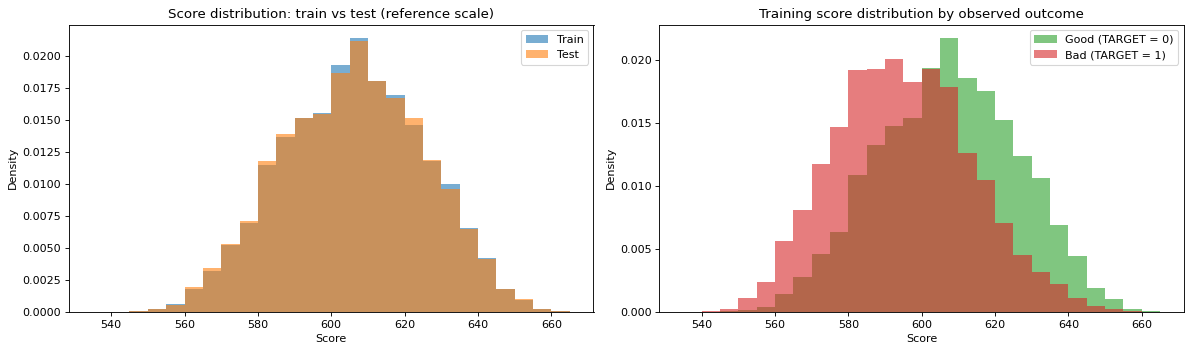

In [22]:
train['score'] = sc.scorecard_ply(train[MODEL_X], card)['score'].values
test['score'] = sc.scorecard_ply(test[MODEL_X], card)['score'].values

rounding_gap = train['score'] - (OFFSET - FACTOR * np.log(pd_train / (1 - pd_train)))
print(f'Scored: train {len(train):,}, test {len(test):,} | max |rounded - unrounded score| on train: {rounding_gap.abs().max():.2f} points')

score_stats = pd.DataFrame({'Train': train['score'].describe(), 'Test': test['score'].describe()}).T
display(score_stats[['count', 'mean', '50%', 'std', 'min', 'max']].rename(columns={'50%': 'median'})
        .style.format({'count': '{:,.0f}', 'mean': '{:.1f}', 'median': '{:.0f}', 'std': '{:.1f}', 'min': '{:.0f}', 'max': '{:.0f}'}))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
score_bins = np.arange(np.floor(min(train['score'].min(), test['score'].min()) / 5) * 5,
                       np.ceil(max(train['score'].max(), test['score'].max()) / 5) * 5 + 5, 5)
axes[0].hist(train['score'], bins=score_bins, alpha=0.6, density=True, label='Train')
axes[0].hist(test['score'], bins=score_bins, alpha=0.6, density=True, label='Test')
axes[0].set_title('Score distribution: train vs test (reference scale)'); axes[0].set_xlabel('Score'); axes[0].set_ylabel('Density'); axes[0].legend()
axes[1].hist(train.loc[train[TARGET] == 0, 'score'], bins=score_bins, alpha=0.6, density=True, label='Good (TARGET = 0)', color='tab:green')
axes[1].hist(train.loc[train[TARGET] == 1, 'score'], bins=score_bins, alpha=0.6, density=True, label='Bad (TARGET = 1)', color='tab:red')
axes[1].set_title('Training score distribution by observed outcome'); axes[1].set_xlabel('Score'); axes[1].set_ylabel('Density'); axes[1].legend()
plt.tight_layout()
plt.show()

**Observed bad rate by score band.** Applicants are split into 10 equal-sized score bands (cut points from the training scores). A working scorecard shows the bad rate falling as the score rises, in both samples.

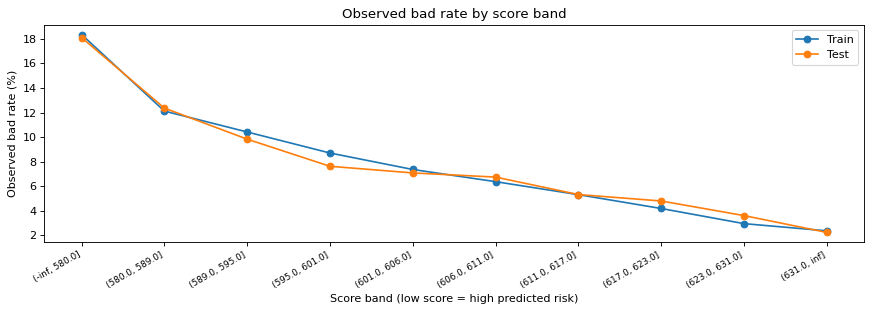

Train: bad rate falls from 18.34% (lowest band) to 2.37% (highest band); falls at every step: True
Test: bad rate falls from 18.09% (lowest band) to 2.24% (highest band); falls at every step: True


In [23]:
_, band_edges = pd.qcut(train['score'], q=10, retbins=True, duplicates='drop')
band_edges[0], band_edges[-1] = -np.inf, np.inf
band_rows = []
for sample, df in [('Train', train), ('Test', test)]:
    g = df.groupby(pd.cut(df['score'], band_edges), observed=True).agg(Applicants=(TARGET, 'size'), Bads=(TARGET, 'sum'))
    g['Bad rate'] = g['Bads'] / g['Applicants']
    g['Sample'] = sample
    band_rows.append(g)
bands = pd.concat(band_rows).reset_index().rename(columns={'score': 'Score band'})
bands['Score band'] = bands['Score band'].astype(str)
order = bands['Score band'].unique()
display(bands.pivot(index='Score band', columns='Sample', values=['Applicants', 'Bad rate']).reindex(order)
        .style.format('{:,.0f}', subset=['Applicants']).format('{:.2%}', subset=['Bad rate']))

fig, ax = plt.subplots(figsize=(11, 4))
for sample, colour in [('Train', 'tab:blue'), ('Test', 'tab:orange')]:
    s = bands[bands['Sample'] == sample]
    ax.plot(range(len(s)), s['Bad rate'] * 100, '-o', color=colour, label=sample)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=30, ha='right', fontsize=8)
ax.set_ylabel('Observed bad rate (%)'); ax.set_xlabel('Score band (low score = high predicted risk)')
ax.set_title('Observed bad rate by score band'); ax.legend()
plt.tight_layout()
plt.show()

for sample in ['Train', 'Test']:
    rates = bands.loc[bands['Sample'] == sample, 'Bad rate'].values
    print(f'{sample}: bad rate falls from {rates[0]:.2%} (lowest band) to {rates[-1]:.2%} (highest band); falls at every step: {bool(np.all(np.diff(rates) < 0))}')

## 6.11 Model Performance (training vs test)

- **ROC AUC**: the probability that a randomly chosen bad applicant receives a higher predicted PD than a randomly chosen good one (0.5 = random, 1.0 = perfect). **Gini** = `2 x AUC - 1`.
- **Brier score** and **log loss**: accuracy of the predicted PDs (lower is better).
- **Mean predicted PD vs actual bad rate**: calibration in the large; the decile calibration check is in Step 7 (7.1).

The test sample was not used for any decision; similar train and test values mean the model generalises to unseen applicants.

,Train,Test,Test - Train
AUC,0.6770,0.6697,-0.0073
Gini,0.3540,0.3394,-0.0145
Brier score,0.0709,0.0710,0.0002
Log loss,0.2629,0.2640,0.0011
Mean predicted PD,0.0796,0.0800,0.0004
Actual bad rate,0.0796,0.0796,0.0000


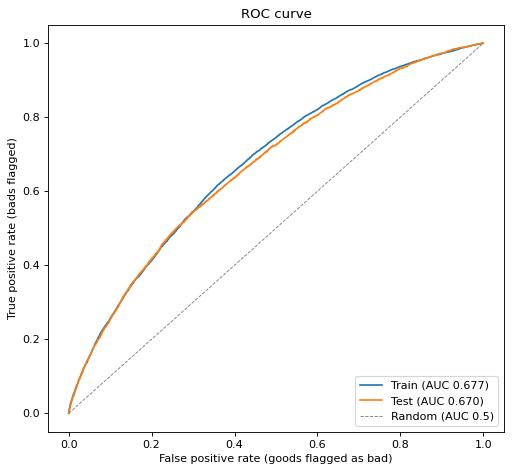

In [24]:
def model_metrics(y, p):
    auc = metrics.roc_auc_score(y, p)
    return {'AUC': auc, 'Gini': 2 * auc - 1, 'Brier score': metrics.brier_score_loss(y, p), 'Log loss': metrics.log_loss(y, p),
            'Mean predicted PD': p.mean(), 'Actual bad rate': y.mean()}

performance = pd.DataFrame({'Train': model_metrics(y_train, pd_train), 'Test': model_metrics(y_test, pd_test)})
performance['Test - Train'] = performance['Test'] - performance['Train']
display(performance.style.format('{:.4f}'))
perf = pd.DataFrame({s: {'ROC AUC (predicted PD)': performance.loc['AUC', s], 'Gini (predicted PD)': performance.loc['Gini', s]} for s in ['Train', 'Test']})

fig, ax = plt.subplots(figsize=(6.5, 6))
for sample, y, p in [('Train', y_train, pd_train), ('Test', y_test, pd_test)]:
    fpr, tpr, _ = metrics.roc_curve(y, p)
    ax.plot(fpr, tpr, label=f'{sample} (AUC {metrics.roc_auc_score(y, p):.3f})')
ax.plot([0, 1], [0, 1], color='grey', linestyle='--', linewidth=0.8, label='Random (AUC 0.5)')
ax.set_xlabel('False positive rate (goods flagged as bad)'); ax.set_ylabel('True positive rate (bads flagged)')
ax.set_title('ROC curve'); ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Interpretation**

- **Discrimination is moderate and generalises.** AUC is 0.677 on training and 0.670 on test (Gini 0.354 vs 0.339). The small gap (0.007) shows no meaningful overfitting.
- **Calibration holds on unseen applicants.** The average predicted PD equals the actual bad rate on training (7.96%) and is within 0.04 percentage points on test.
- **Higher scores mean lower risk.** The observed bad rate falls at every step across the 10 score bands, in both samples: from about 18% in the lowest band to about 2.3% in the highest.
- **A Gini of about 0.34 is modest for an application scorecard,** consistent with the weak-to-medium IVs of the characteristics (Step 5). Goods and bads overlap considerably in score.

## 6.12 Scorecard Summary

The scorecard on the reference scale (600 at the portfolio odds, PDO 20). The approval cutoff and final scale are set in Step 7 (`07_scorecard analysis.ipynb`).

In [25]:
summary = pd.DataFrame({'Result': {
    'Training / testing applicants': f'{len(train):,} / {len(test):,}',
    'Characteristics in the model': f'{len(MODEL_X)} ({", ".join(MODEL_X)})',
    'Excluded from the regression (coefficient sign)': ', '.join(REMOVED_FOR_SIGN) or 'none',
    'Logistic regression configuration': LR_CONFIG,
    'Logistic regression intercept': f'{lr.intercept_[0]:+.4f}',
    'Reference scale': f'{POINTS0} at 1 : {1 / ODDS0_REFERENCE:.2f}, PDO {PDO}',
    'Score range (train)': f'{train["score"].min():.0f} - {train["score"].max():.0f}',
    'Training AUC / Gini': f'{perf.loc["ROC AUC (predicted PD)", "Train"]:.4f} / {perf.loc["Gini (predicted PD)", "Train"]:.4f}',
    'Testing AUC / Gini': f'{perf.loc["ROC AUC (predicted PD)", "Test"]:.4f} / {perf.loc["Gini (predicted PD)", "Test"]:.4f}',
    'Manual vs sc.scorecard_ply scores': 'identical for all 3 applicants' if (verification['Difference'] == 0).all() else 'differences found',
}})
display(summary)
print(formula)

,Result
Training / testing applicants,"149,318 / 63,994"
Characteristics in the model,"11 (EMPLOYMENT_YEARS, CREDIT_TO_GOODS_RATIO, ACTIVE_LOAN_RATIO, MOST_RECENT_CREDIT_AGE, OCCUPATION_TYPE, OLDEST_CRED..."
Excluded from the regression (coefficient sign),BUREAU_DEBT_TO_INCOME
Logistic regression configuration,Standard
Logistic regression intercept,-2.4491
Reference scale,"600 at 1 : 11.56, PDO 20"
Score range (train),543 - 664
Training AUC / Gini,0.6770 / 0.3540
Testing AUC / Gini,0.6697 / 0.3394
Manual vs sc.scorecard_ply scores,identical for all 3 applicants


Logit(PD) = -2.4491
            +0.6787 x EMPLOYMENT_YEARS_woe
            +0.8300 x CREDIT_TO_GOODS_RATIO_woe
            +0.3213 x ACTIVE_LOAN_RATIO_woe
            +0.3766 x MOST_RECENT_CREDIT_AGE_woe
            +0.4526 x OCCUPATION_TYPE_woe
            +0.3806 x OLDEST_CREDIT_AGE_woe
            +0.5701 x ACTIVE_LOAN_COUNT_woe
            +0.2485 x NAME_INCOME_TYPE_woe
            +0.8112 x DEBT_TO_CREDIT_RATIO_woe
            +0.8363 x NAME_EDUCATION_TYPE_woe
            +0.2207 x MICROLOAN_COUNT_woe


## 6.13 Save the Model for Step 7

Step 7 (`07_scorecard analysis.ipynb`) chooses the approval cutoff and the final score scale. So that it uses **exactly** this model, the objects it needs are saved to `data/step6_scorecard_model.pkl`: the approved scorecardpy bins, the fitted logistic regression, the reference-scale scorecard and its parameters. Step 7 loads them; it does not re-bin or re-fit anything.

In [26]:
import pickle

ids = pd.concat([train[ID], test[ID]]).values
step6 = {
    'bins': bins, 'lr': lr, 'card': card, 'LR_CONFIG': LR_CONFIG, 'configs': configs,
    'X_COLS': X_COLS, 'MODEL_X': MODEL_X, 'REMOVED_FOR_SIGN': REMOVED_FOR_SIGN, 'breaks_list': breaks_list, 'formula': formula, 'coefficients': coefficients, 'perf': perf,
    'POINTS0': POINTS0, 'PDO': PDO, 'ODDS0_REFERENCE': ODDS0_REFERENCE, 'TARGET_BAD_RATE': TARGET_BAD_RATE,
    'pd_12': pd.Series(np.concatenate([pd_train, pd_test]), index=ids),
    'score_reference': pd.Series(np.concatenate([train['score'].values, test['score'].values]), index=ids),
}
with open('data/step6_scorecard_model.pkl', 'wb') as f:
    pickle.dump(step6, f)
print('Saved data/step6_scorecard_model.pkl:', ', '.join(step6))

# inputs unchanged
assert pd.read_csv('data/final_characteristics.csv').equals(final_original)
print('final_characteristics.csv unchanged; encoded.csv written; Step 6 complete')

Saved data/step6_scorecard_model.pkl: bins, lr, card, LR_CONFIG, configs, X_COLS, MODEL_X, REMOVED_FOR_SIGN, breaks_list, formula, coefficients, perf, POINTS0, PDO, ODDS0_REFERENCE, TARGET_BAD_RATE, pd_12, score_reference


final_characteristics.csv unchanged; encoded.csv written; Step 6 complete
